1232 / 2000 values seen with frequency 16. the largest of which was 1999
768 / 2000 values seen with frequency 17. the largest of which was 767
32768 mod 2000 = 768


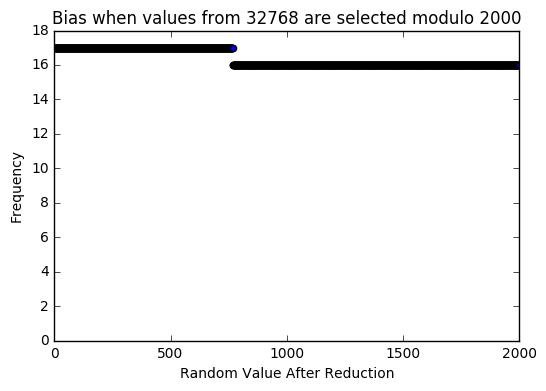

In [40]:
from collections import Counter
from matplotlib import pyplot as plt

# constants for the experiment
RF = RealField(64)
RAND_MAX = 32768
MODULUS = 2000
frequency_counter = Counter()

def values_with_frequency(frequencies, frequency):
    # returns the set of keys in `frequencies` with 
    # a specific `frequency` value.
    fs = []
    for k, v in frequencies.items():
        if v == frequency:
            fs.append(k)
    return fs

def count_values_with_frequency(frequencies, frequency):
    # counts the number of times a random value with a specific
    # `frequency` was seen in `frequencies`.
    count = 0
    for _, v in frequencies.items():
        if v == frequency:
            count += 1
    return count

def enumerate_frequencies():
    for i in range(RAND_MAX):
        frequency_counter[i % MODULUS] += 1

enumerate_frequencies()       
labels, values = zip(*frequency_counter.items())
counts = set(frequency_counter.values())

for c in counts:
    fc = count_values_with_frequency(frequency_counter, c)
    mc = max(values_with_frequency(frequency_counter, c))
    print("%d / %d values seen with frequency %d. the largest of which was %d" % (fc, MODULUS, c, mc))
print("%d mod %d = %d" % (RAND_MAX, MODULUS, RAND_MAX % MODULUS))
    
plt.scatter(labels, values)
plt.axis([0, MODULUS-1, 0, (RAND_MAX//MODULUS)+2])
plt.xlabel("Random Value After Reduction")
plt.ylabel("Frequency")
plt.title("Bias when values from %d are selected modulo %d" % (RAND_MAX, MODULUS))
plt.show()